# Exploratory Data Analysis

In [ ]:
# Access ACLED events data
import boto3
import duckdb
s3 = boto3.client("s3")
s3.download_file("dsan6000-data", "acled_events.parquet", "events.parquet")

events_con = duckdb.connect()

events_query = """
SELECT * FROM 'events.parquet' LIMIT 5
"""
events_head_df = events_con.execute(events_query).df()

In [ ]:
# Show first five events
events_head_df

,event_id_cnty,event_date,year,time_precision,disorder_type,event_type,sub_event_type,actor1,assoc_actor_1,inter1,...,location,latitude,longitude,geo_precision,source,source_scale,notes,fatalities,tags,timestamp
0,RWA3,1997-01-01,1997,1,Political violence,Battles,Armed clash,Military Forces of Rwanda (1994-),None,State forces,...,Gafunzo,-2.3927,29.0044,1,Local Source,International,Security forces kill a rebel officer who had b...,1,None,1618568810
1,ALG1,1997-01-01,1997,1,Political violence,Violence against civilians,Attack,GIA: Armed Islamic Group,None,Rebel group,...,Douaouda,36.6725,2.7894,1,Algeria Watch,Other,5 January: Beheading of 5 citizens in Douaouda...,5,None,1582579226
2,SIE1,1997-01-01,1997,3,Strategic developments,Strategic developments,Looting/property destruction,RUF: Revolutionary United Front,None,Rebel group,...,Magburaka,8.7167,-11.9500,3,SL-LED; No Peace Without Justice,Local partner-New media,Looting,0,None,1607978719
3,SIE4,1997-01-01,1997,3,Strategic developments,Strategic developments,Looting/property destruction,Kamajor Militia,None,Political militia,...,Badjia,7.4338,-12.2419,2,No Peace Without Justice; SL-LED,Local partner-New media,Looting,0,None,1607978767
4,SIE5,1997-01-01,1997,3,Strategic developments,Strategic developments,Looting/property destruction,Kamajor Militia,None,Political militia,...,Valunia,8.3172,-11.7336,2,No Peace Without Justice; SL-LED,Local partner-New media,Looting,0,None,1607978771


In [ ]:
# Column Names and Types
events_con.execute("SELECT * FROM parquet_schema('events.parquet')").df()

,file_name,name,type,type_length,repetition_type,num_children,converted_type,scale,precision,field_id,logical_type,duckdb_type,column_id
0,events.parquet,schema,NaN,None,REQUIRED,31,NaN,<NA>,<NA>,<NA>,NaN,NaN,0
1,events.parquet,event_id_cnty,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,1
2,events.parquet,event_date,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,2
3,events.parquet,year,INT64,None,OPTIONAL,<NA>,NaN,<NA>,<NA>,<NA>,NaN,BIGINT,3
4,events.parquet,time_precision,INT64,None,OPTIONAL,<NA>,NaN,<NA>,<NA>,<NA>,NaN,BIGINT,4
5,events.parquet,disorder_type,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,5
6,events.parquet,event_type,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,6
7,events.parquet,sub_event_type,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,7
8,events.parquet,actor1,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,8
9,events.parquet,assoc_actor_1,BYTE_ARRAY,None,OPTIONAL,<NA>,UTF8,<NA>,<NA>,<NA>,StringType(),VARCHAR,9


In [13]:
# Look at the split of event types
events_query = """
SELECT "event_type", COUNT(*) AS Count
FROM 'events.parquet'
GROUP BY "event_type"
ORDER BY Count DESC
"""
events_con.sql(events_query).show()

┌────────────────────────────┬─────────┐
│         event_type         │  Count  │
│          varchar           │  int64  │
├────────────────────────────┼─────────┤
│ Protests                   │ 1124970 │
│ Explosions/Remote violence │  498745 │
│ Battles                    │  455519 │
│ Violence against civilians │  320599 │
│ Strategic developments     │  201185 │
│ Riots                      │  180015 │
└────────────────────────────┴─────────┘



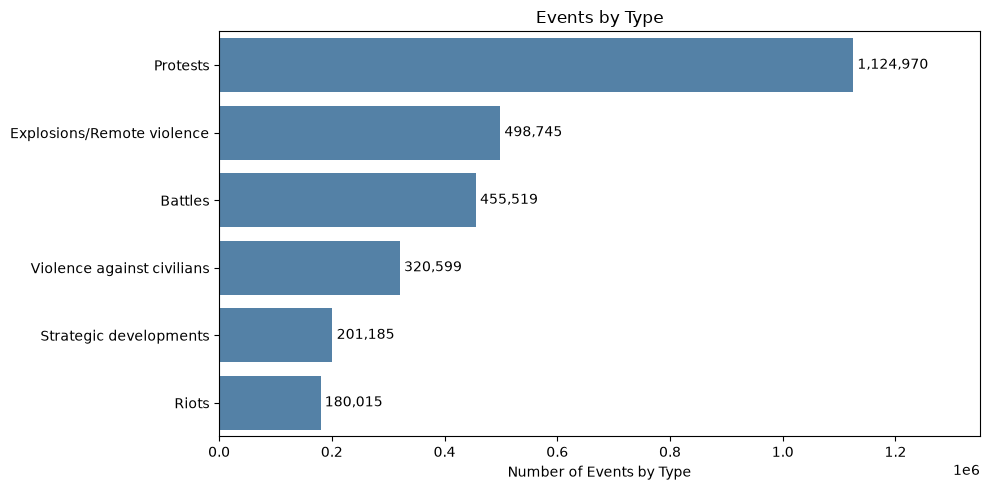

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

counts_df = events_con.execute(events_query).df()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=counts_df, x="Count", y="event_type", color="steelblue", ax=ax)

ax.set_xlabel("Number of Events by Type")
ax.set_ylabel("")
ax.set_title("Events by Type")
ax.margins(x=0.2)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)  # count at the end of each bar

plt.tight_layout()
plt.show()

In [19]:
# Look at the split of region events
regions_query = """
SELECT "region", COUNT(*) AS Count
FROM 'events.parquet'
GROUP BY "region"
ORDER BY Count DESC
"""
events_con.sql(regions_query).show()

┌───────────────────────────┬────────┐
│          region           │ Count  │
│          varchar          │ int64  │
├───────────────────────────┼────────┤
│ Middle East               │ 556759 │
│ Europe                    │ 522204 │
│ South Asia                │ 368897 │
│ South America             │ 247885 │
│ North America             │ 208570 │
│ Southeast Asia            │ 157736 │
│ Eastern Africa            │ 140776 │
│ Caucasus and Central Asia │ 109155 │
│ Western Africa            │ 102923 │
│ Northern Africa           │ 101253 │
│ East Asia                 │  81923 │
│ Middle Africa             │  78931 │
│ Central America           │  35185 │
│ Southern Africa           │  34615 │
│ Caribbean                 │  25334 │
│ Oceania                   │   7362 │
│ International Waters      │   1517 │
│ Antarctica                │      8 │
└───────────────────────────┴────────┘
  18 rows                  2 columns



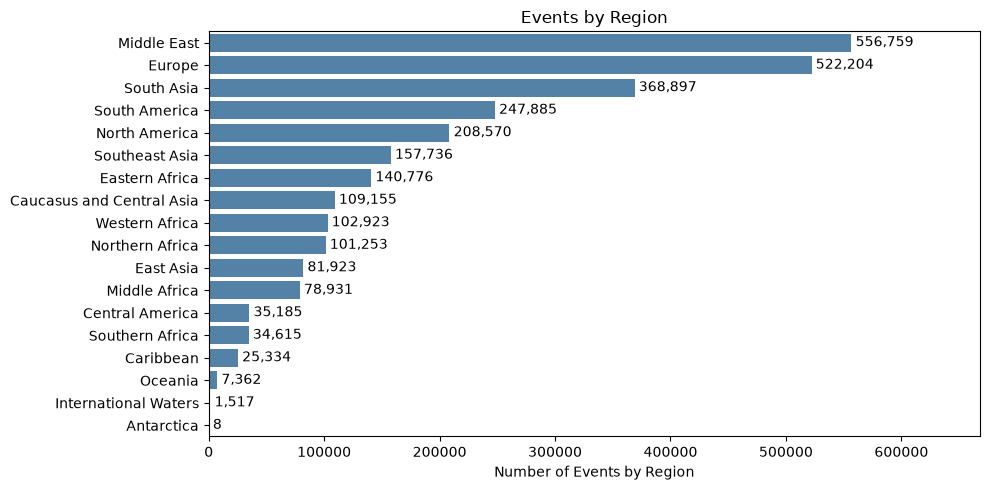

In [20]:
# Plot events by region
regions_df = events_con.execute(regions_query).df()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=regions_df, x="Count", y="region", color="steelblue", ax=ax)

ax.set_xlabel("Number of Events by Region")
ax.set_ylabel("")
ax.set_title("Events by Region")
ax.margins(x=0.2)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)  # count at the end of each bar

plt.tight_layout()
plt.show()

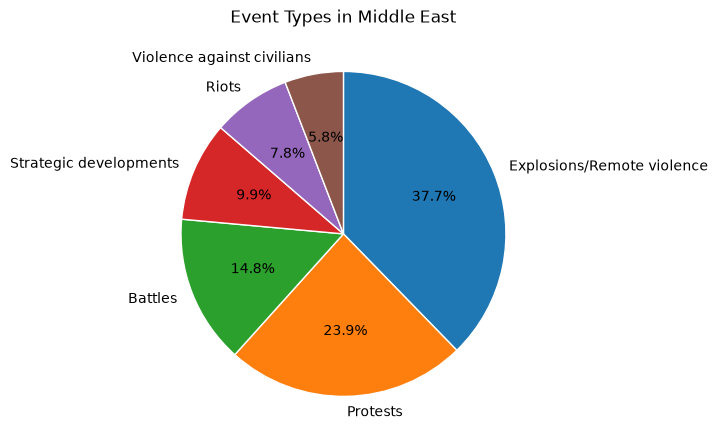

In [28]:
# Look at events in Middle East since it has the most
# (we can reuse this code block for other regions if needed)
region = "Middle East"

me_query = """
SELECT "event_type", COUNT(*) AS Count
FROM 'events.parquet'
WHERE region = ?
GROUP BY "event_type"
ORDER BY Count DESC
"""
me_df = events_con.execute(me_query, [region]).df()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    me_df["Count"],
    labels=me_df['event_type'],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white"},
)
ax.set_title(f"Event Types in {region}")
plt.tight_layout()
plt.show()